# TP 1 — Recherche des plus proches voisins (NN search)

**Cours :** *Nearest-Neighbors Search* (slides 19–40) — linear scan, k-d trees, recherche *defeatist* vs *backtracking*, malédiction de la dimension.

**À la fin de ce notebook, vous saurez :**
1. coder un *linear scan* vectorisé (1-NN et k-NN) ;
2. construire un **k-d tree** (médiane, coordonnées cycliques) et y faire une recherche **defeatist** puis **backtracking** ;
3. mesurer quand le k-d tree bat le linear scan… et quand il ne sert plus à rien (malédiction de la dimension) ;
4. l'appliquer à une recherche d'**analogues de marché** (« quels jours passés ressemblent à aujourd'hui ? »), brique de base des méthodes k-NN en recherche quantitative.

| Partie | Contenu | Données |
|---|---|---|
| 1 | Linear scan | simulées |
| 2 | k-d tree : construction, defeatist, backtracking, k-NN | simulées |
| 3 | Benchmarks, malédiction de la dimension | simulées |
| 4 | Application : analogues de marché sur ETF sectoriels | réelles (yfinance) ou simulées |
| 5 | Synthèse : quel algo, quand | — |

> 📗 **Version corrigée.** Toutes les cellules s'exécutent de bout en bout.

In [1]:
import sys, pathlib, warnings
_here = pathlib.Path.cwd()
ROOT = _here.parent if _here.name in ("exercices", "corriges") else _here
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tp_utils import *          # style graphique, check(), check_close(), timer()...
import tp_data                  # données réelles (cache / téléchargement) ou simulées

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
rng = np.random.default_rng(42)
from scipy.spatial import cKDTree

## Partie 1 — Linear scan

Le problème : étant donné un nuage $P = \{p_1,\dots,p_n\} \subset \mathbb{R}^d$ (pré-traitement possible) et une requête $q$, trouver $p \in P$ minimisant $\|q - p\|_2$.

La solution naïve parcourt tous les points : $O(dn)$ en temps, aucun pré-traitement. C'est **la référence** que toute structure de données doit battre. En NumPy, on la vectorise : jamais de boucle Python sur les points.

### Exercice 1.1 — `linear_scan` et `linear_scan_knn`
- `linear_scan(P, q)` renvoie `(indice, distance)` du plus proche voisin.
- `linear_scan_knn(P, q, k)` renvoie les indices des `k` plus proches voisins **triés par distance croissante**, et leurs distances. Utilisez `np.argpartition` (sélection en $O(n)$) puis triez seulement les `k` gagnants.

In [2]:
def linear_scan(P, q):
    """Plus proche voisin de q dans P (n x d) par parcours exhaustif.
    Retourne (indice, distance)."""
    d = np.sqrt(((P - q) ** 2).sum(axis=1))
    i = int(np.argmin(d))
    return i, float(d[i])


def linear_scan_knn(P, q, k):
    """k plus proches voisins de q (indices triés par distance croissante, distances)."""
    d = np.sqrt(((P - q) ** 2).sum(axis=1))
    k = min(k, len(P))
    idx = np.argpartition(d, k - 1)[:k]
    idx = idx[np.argsort(d[idx])]
    return idx, d[idx]

In [3]:
# Test
P = rng.random((2000, 3)); q = rng.random(3)
ref = cKDTree(P)
d_ref, i_ref = ref.query(q, k=5)
i, d = linear_scan(P, q)
check(i == i_ref[0] and np.isclose(d, d_ref[0]), "linear_scan = cKDTree (1-NN)")
idx, dist = linear_scan_knn(P, q, 5)
check_close(dist, d_ref, "linear_scan_knn : distances des 5-NN")
check(np.all(idx == i_ref), "linear_scan_knn : indices triés")

✅ linear_scan = cKDTree (1-NN)
✅ linear_scan_knn : distances des 5-NN
✅ linear_scan_knn : indices triés


## Partie 2 — k-d tree

Un k-d tree est un **arbre binaire de partitions de l'espace** : chaque nœud interne coupe le nuage courant par un hyperplan orthogonal à un axe $c$, passant par la **médiane** des coordonnées $p[c]$ ; on change d'axe de façon cyclique, $c \leftarrow (c+1) \bmod d$. On s'arrête quand il reste au plus $n_0$ points (feuille).

Pseudo-code du cours (slide 28) :
```
build(P, c):
    si #P <= n0 : créer une feuille contenant P
    sinon :
        m  = médiane de {p[c] : p ∈ P},   p* ∈ P tel que p*[c] = m
        Pl = {p ∈ P : p[c] <= m} \ {p*},   Pr = {p ∈ P : p[c] > m}
        nœud interne (c, m, p*, build(Pl, (c+1)%d), build(Pr, (c+1)%d))
```

**Choix d'implémentation.** On ne copie jamais les points : chaque nœud manipule un tableau d'**indices** dans `P`. Pour la médiane, `np.argpartition(vals, k)[k]` donne en $O(\#P)$ la position du $k$-ième plus petit élément (même idée que QuickSelect) — d'où une construction en $O(n \log n)$.

In [4]:
class Leaf:
    __slots__ = ("idx",)
    def __init__(self, idx):
        self.idx = idx            # indices (dans P) des points de la feuille

class Node:
    __slots__ = ("axis", "m", "p", "left", "right")
    def __init__(self, axis, m, p, left, right):
        self.axis, self.m, self.p = axis, m, p   # axe de coupe, valeur médiane, indice de p*
        self.left, self.right = left, right       # gauche : p[axis] <= m ; droite : > m

### Exercice 2.1 — Construction

In [5]:
def build_kdtree(P, n0=10):
    """Construit le k-d tree de P (n x d) ; feuilles d'au plus n0 points."""
    n, d = P.shape

    def build(idx, c):
        if len(idx) <= n0:
            return Leaf(idx)
        vals = P[idx, c]
        k = len(idx) // 2
        j = np.argpartition(vals, k)[k]          # position de la médiane dans idx
        m = vals[j]
        left_mask = vals <= m
        left_mask[j] = False                     # p* est stocké dans le nœud, pas dans Pl
        nxt = (c + 1) % d
        return Node(c, m, idx[j], build(idx[left_mask], nxt), build(idx[vals > m], nxt))

    return build(np.arange(n), 0)


def tree_stats(node, depth=0):
    """(nombre de points stockés, hauteur, nombre de feuilles)"""
    if isinstance(node, Leaf):
        return len(node.idx), depth, 1
    a = tree_stats(node.left, depth + 1)
    b = tree_stats(node.right, depth + 1)
    return a[0] + b[0] + 1, max(a[1], b[1]), a[2] + b[2]

In [6]:
# Test
P = rng.random((5000, 2))
tree = build_kdtree(P, n0=10)
n_pts, h, n_leaves = tree_stats(tree)
check(n_pts == len(P), "chaque point est stocké exactement une fois")
check(h <= np.ceil(np.log2(len(P) / 10)) + 2, f"arbre équilibré (hauteur {h} ≈ log2(n/n0) = {np.log2(len(P)/10):.1f})")

✅ chaque point est stocké exactement une fois
✅ arbre équilibré (hauteur 9 ≈ log2(n/n0) = 9.0)


Visualisons la partition induite (chaque segment = un nœud interne ; les coupes alternent verticales / horizontales).

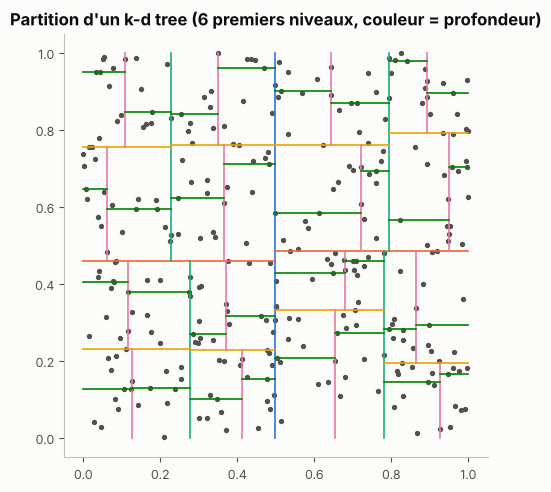

In [7]:
def plot_kdtree(ax, node, P, box, depth=0, max_depth=7):
    if isinstance(node, Leaf) or depth >= max_depth:
        return
    (x0, x1), (y0, y1) = box
    if node.axis == 0:
        ax.plot([node.m, node.m], [y0, y1], color=PALETTE[depth % 8], lw=1.2)
        plot_kdtree(ax, node.left, P, ((x0, node.m), (y0, y1)), depth + 1, max_depth)
        plot_kdtree(ax, node.right, P, ((node.m, x1), (y0, y1)), depth + 1, max_depth)
    else:
        ax.plot([x0, x1], [node.m, node.m], color=PALETTE[depth % 8], lw=1.2)
        plot_kdtree(ax, node.left, P, ((x0, x1), (y0, node.m)), depth + 1, max_depth)
        plot_kdtree(ax, node.right, P, ((x0, x1), (node.m, y1)), depth + 1, max_depth)

Psmall = rng.random((300, 2))
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(*Psmall.T, s=8, color=INK2)
plot_kdtree(ax, build_kdtree(Psmall, n0=5), Psmall, ((0, 1), (0, 1)), max_depth=6)
ax.set_title("Partition d'un k-d tree (6 premiers niveaux, couleur = profondeur)"); ax.set_aspect("equal"); ax.grid(False)
plt.show()

### Exercice 2.2 — Recherche *defeatist*

On descend de la racine vers **une seule** feuille, en suivant le côté de l'hyperplan où se trouve $q$, et en mettant à jour $d_{\min}$ avec le point $p^*$ de chaque nœud traversé puis avec les points de la feuille. Coût $O(d(n_0 + \log(n/n_0)))$… mais **la réponse peut être fausse** : le vrai plus proche voisin peut se trouver de l'autre côté d'une coupe.

La fonction renvoie aussi `n_dist`, le nombre de distances calculées : c'est la bonne mesure du coût, indépendante de la vitesse de Python.

In [8]:
def defeatist_search(tree, P, q):
    """Retourne (indice, distance, n_dist)."""
    best_i, best_d, n_dist = -1, np.inf, 0
    node = tree
    while isinstance(node, Node):
        dp = np.sqrt(((P[node.p] - q) ** 2).sum()); n_dist += 1
        if dp < best_d:
            best_i, best_d = node.p, dp
        node = node.left if q[node.axis] <= node.m else node.right
    if len(node.idx):
        D = np.sqrt(((P[node.idx] - q) ** 2).sum(axis=1)); n_dist += len(node.idx)
        j = np.argmin(D)
        if D[j] < best_d:
            best_i, best_d = int(node.idx[j]), float(D[j])
    return best_i, float(best_d), n_dist

In [9]:
# Test : defeatist ne se trompe jamais par excès (d >= vraie distance), mais se trompe parfois
P = rng.random((5000, 2)); tree = build_kdtree(P, n0=10)
Q = rng.random((500, 2))
true_d = cKDTree(P).query(Q)[0]
res = np.array([defeatist_search(tree, P, q)[1] for q in Q])
check(np.all(res >= true_d - 1e-12), "defeatist renvoie une distance >= distance du vrai NN")
fail = np.mean(res > true_d + 1e-12)
check(0 < fail < 0.5, f"defeatist échoue sur une fraction non nulle des requêtes ({fail:.1%})")

✅ defeatist renvoie une distance >= distance du vrai NN
✅ defeatist échoue sur une fraction non nulle des requêtes (14.8%)


### Exercice 2.3 — Recherche *backtracking*

On explore un sous-arbre **seulement si la boule** $B(q, d_{\min})$ **intersecte** la demi-espace correspondant. Avec $\delta = q[c] - m$ :
- on explore d'abord le côté **proche** (celui qui contient $q$) — c'est une amélioration pratique du pseudo-code du cours : $d_{\min}$ diminue vite, ce qui élague davantage ;
- on explore le côté **lointain** seulement si $|\delta| \le d_{\min}$ (la boule traverse l'hyperplan).

La réponse est **toujours exacte**. Le coût est $O(c_d \log n)$ dans le cas favorable ($c_d \approx 2^d$), mais peut devenir linéaire.

In [10]:
def backtracking_search(tree, P, q):
    """Plus proche voisin exact. Retourne (indice, distance, n_dist)."""
    best = {"i": -1, "d": np.inf, "n": 0}

    def search(node):
        if isinstance(node, Leaf):
            if len(node.idx):
                D = np.sqrt(((P[node.idx] - q) ** 2).sum(axis=1)); best["n"] += len(node.idx)
                j = np.argmin(D)
                if D[j] < best["d"]:
                    best["i"], best["d"] = int(node.idx[j]), float(D[j])
            return
        dp = np.sqrt(((P[node.p] - q) ** 2).sum()); best["n"] += 1
        if dp < best["d"]:
            best["i"], best["d"] = node.p, dp
        delta = q[node.axis] - node.m
        near, far = (node.left, node.right) if delta <= 0 else (node.right, node.left)
        search(near)
        if abs(delta) <= best["d"]:
            search(far)

    search(tree)
    return best["i"], float(best["d"]), best["n"]

In [11]:
# Test
res = [backtracking_search(tree, P, q) for q in Q]
check_close([r[1] for r in res], true_d, "backtracking = vrai plus proche voisin (500 requêtes)")
print(f"distances calculées en moyenne : {np.mean([r[2] for r in res]):.0f} sur n = {len(P)}")

✅ backtracking = vrai plus proche voisin (500 requêtes)
distances calculées en moyenne : 25 sur n = 5000


### Exercice 2.4 (bonus utile) — k plus proches voisins par backtracking

Même principe, mais on maintient les $k$ meilleurs candidats dans un **tas** (`heapq`, tas-min : on y stocke $(-d, i)$ pour avoir le pire candidat au sommet). Le rayon d'élagage devient la distance du $k$-ième candidat (∞ tant qu'on en a moins de $k$). Ce sera la brique des prédicteurs k-NN du TP 5.

In [12]:
import heapq

def knn_backtracking(tree, P, q, k):
    """k plus proches voisins exacts. Retourne (indices triés, distances, n_dist)."""
    heap = []                 # éléments (-distance, indice) ; heap[0] = pire des k meilleurs
    count = [0]

    def radius():
        return -heap[0][0] if len(heap) == k else np.inf

    def push(i, dist):
        if len(heap) < k:
            heapq.heappush(heap, (-dist, i))
        elif dist < -heap[0][0]:
            heapq.heapreplace(heap, (-dist, i))

    def search(node):
        if isinstance(node, Leaf):
            if len(node.idx):
                D = np.sqrt(((P[node.idx] - q) ** 2).sum(axis=1)); count[0] += len(node.idx)
                for i, dist in zip(node.idx, D):
                    push(int(i), float(dist))
            return
        push(node.p, float(np.sqrt(((P[node.p] - q) ** 2).sum()))); count[0] += 1
        delta = q[node.axis] - node.m
        near, far = (node.left, node.right) if delta <= 0 else (node.right, node.left)
        search(near)
        if abs(delta) <= radius():
            search(far)

    search(tree)
    out = sorted((-nd, i) for nd, i in heap)
    return np.array([i for _, i in out]), np.array([dd for dd, _ in out]), count[0]

In [13]:
# Test
d_ref, i_ref = cKDTree(P).query(Q[:50], k=7)
ok = all(np.allclose(knn_backtracking(tree, P, q, 7)[1], d_ref[j]) for j, q in enumerate(Q[:50]))
check(ok, "knn_backtracking = cKDTree (k = 7, 50 requêtes)")

✅ knn_backtracking = cKDTree (k = 7, 50 requêtes)


## Partie 3 — Benchmarks et malédiction de la dimension

### 3.1 Coût en fonction de $n$ (uniforme dans le carré unité, $d = 2$)

On mesure le nombre moyen de distances calculées par requête (linear scan : exactement $n$).

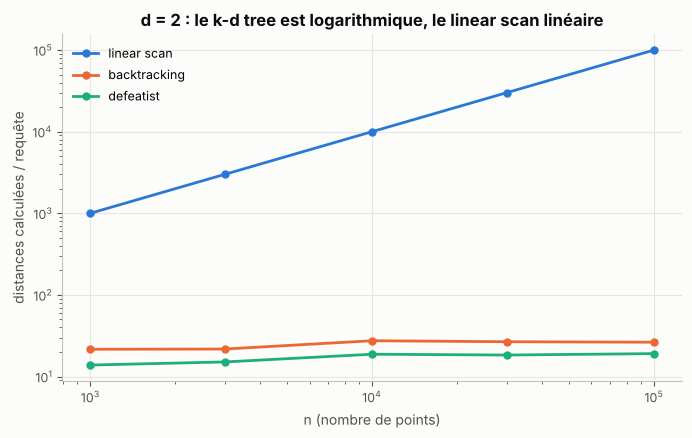

,n,linear scan,backtracking,defeatist
0,1000,1000,21.595,13.835
1,3000,3000,21.735,15.100
2,10000,10000,27.465,18.775
3,30000,30000,26.705,18.345
4,100000,100000,26.345,19.095


In [14]:
ns = [1_000, 3_000, 10_000, 30_000, 100_000]
rows = []
for n in ns:
    P = rng.random((n, 2)); tree = build_kdtree(P, n0=10); Q = rng.random((200, 2))
    nd_back = np.mean([backtracking_search(tree, P, q)[2] for q in Q])
    nd_def = np.mean([defeatist_search(tree, P, q)[2] for q in Q])
    rows.append((n, n, nd_back, nd_def))
bench_n = pd.DataFrame(rows, columns=["n", "linear scan", "backtracking", "defeatist"])

fig, ax = plt.subplots()
for col in ["linear scan", "backtracking", "defeatist"]:
    ax.loglog(bench_n["n"], bench_n[col], marker="o", label=col)
ax.set_xlabel("n (nombre de points)"); ax.set_ylabel("distances calculées / requête")
ax.set_title("d = 2 : le k-d tree est logarithmique, le linear scan linéaire"); ax.legend()
plt.show()
bench_n

### 3.2 Coût en fonction de la dimension $d$ ($n = 10\,000$, uniforme dans $[0,1]^d$)

Deux quantités : la **fraction de points visités** par le backtracking (1 = aussi cher que le linear scan) et le **taux d'échec** de la recherche defeatist.

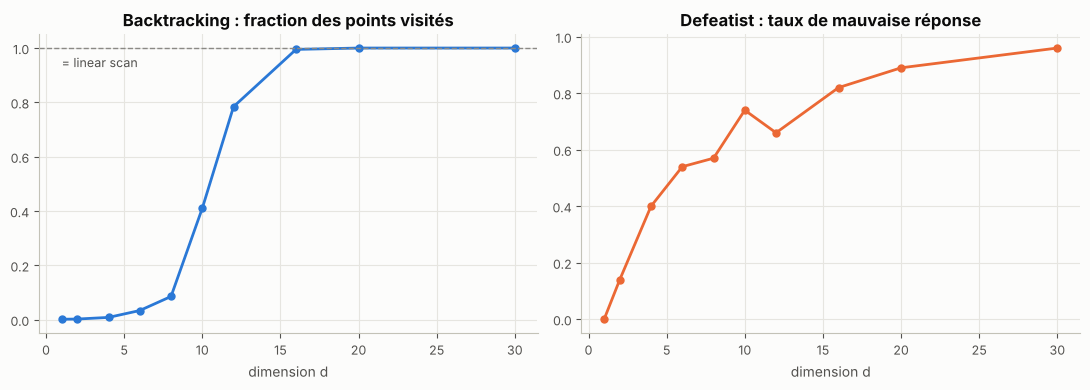

,d,fraction visitée (backtracking),échec defeatist
0,1,0.0020,0.00
1,2,0.0027,0.14
2,4,0.0087,0.40
3,6,0.0340,0.54
4,8,0.0858,0.57
5,10,0.4103,0.74
6,12,0.7841,0.66
7,16,0.9950,0.82
8,20,1.0000,0.89
9,30,1.0000,0.96


In [15]:
dims = [1, 2, 4, 6, 8, 10, 12, 16, 20, 30]
rows = []
for d in dims:
    P = rng.random((10_000, d)); tree = build_kdtree(P, n0=10); Q = rng.random((100, d))
    true_d = cKDTree(P).query(Q)[0]
    back = np.mean([backtracking_search(tree, P, q)[2] for q in Q]) / len(P)
    fail = np.mean([defeatist_search(tree, P, q)[1] > td + 1e-12 for q, td in zip(Q, true_d)])
    rows.append((d, back, fail))
bench_d = pd.DataFrame(rows, columns=["d", "fraction visitée (backtracking)", "échec defeatist"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(bench_d["d"], bench_d.iloc[:, 1], marker="o", color=BLUE)
axes[0].axhline(1, color=GRAY, ls="--", lw=1); axes[0].text(1, 0.93, "= linear scan", color=INK2, fontsize=9)
axes[0].set_xlabel("dimension d"); axes[0].set_title("Backtracking : fraction des points visités")
axes[1].plot(bench_d["d"], bench_d.iloc[:, 2], marker="o", color=ORANGE)
axes[1].set_xlabel("dimension d"); axes[1].set_title("Defeatist : taux de mauvaise réponse")
plt.tight_layout(); plt.show()
bench_d

### 3.3 Pourquoi ? La concentration des distances

En grande dimension, toutes les distances entre points aléatoires deviennent presque égales : le **contraste relatif** $(d_{\max} - d_{\min})/d_{\min}$ vu depuis une requête tend vers 0. Un « plus proche voisin » n'est alors guère plus proche que les autres, et aucune coupe ne permet d'éliminer une région de l'espace.

### Exercice 3.1 — Contraste relatif
Pour chaque dimension, tirez $n = 2000$ points et 50 requêtes uniformes dans $[0,1]^d$ ; calculez la moyenne de $(d_{\max} - d_{\min})/d_{\min}$.

✅ le contraste s'effondre quand d augmente


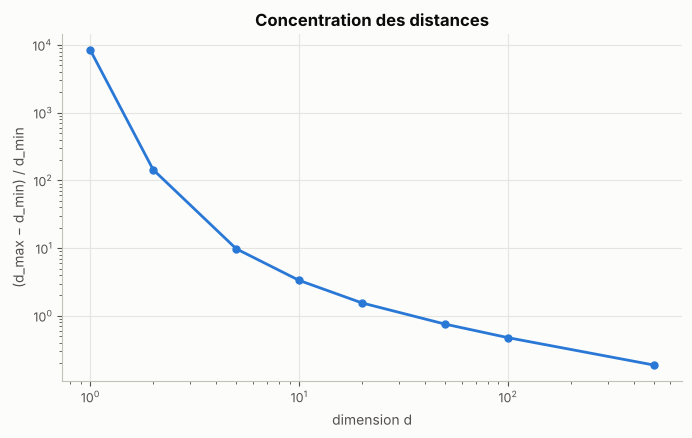

In [16]:
def relative_contrast(d, n=2000, n_queries=50, rng=rng):
    P = rng.random((n, d)); Q = rng.random((n_queries, d))
    D = np.sqrt(((Q[:, None, :] - P[None, :, :]) ** 2).sum(-1))
    return float(np.mean((D.max(1) - D.min(1)) / D.min(1)))

dims_c = [1, 2, 5, 10, 20, 50, 100, 500]
contrast = [relative_contrast(d) for d in dims_c]
check(contrast[0] > 10 * contrast[-1], "le contraste s'effondre quand d augmente")

fig, ax = plt.subplots()
ax.loglog(dims_c, contrast, marker="o")
ax.set_xlabel("dimension d"); ax.set_ylabel("(d_max − d_min) / d_min")
ax.set_title("Concentration des distances")
plt.show()

### 3.4 Et en pratique ? Comparaison des temps avec `scipy.spatial.cKDTree` (implémentation C)

Notre arbre Python sert à **comprendre** ; en production on utilise `scipy.spatial.cKDTree` / `sklearn.neighbors.KDTree`, ou pour la grande dimension des méthodes **approchées** (LSH, arbres à projections aléatoires, graphes HNSW, FAISS). Mesurons, à $n$ fixé, le temps d'un batch de requêtes pour le linear scan vectorisé et pour `cKDTree`.

In [17]:
rows = []
for d in [2, 5, 10, 20, 50]:
    P = rng.random((20_000, d)); Q = rng.random((500, d))
    t_lin = timeit(lambda: [linear_scan(P, q) for q in Q], repeat=1)
    kd = cKDTree(P)
    t_kd = timeit(lambda: kd.query(Q), repeat=1)
    rows.append((d, 1e6 * t_lin / len(Q), 1e6 * t_kd / len(Q)))
pd.DataFrame(rows, columns=["d", "linear scan (µs/requête)", "cKDTree (µs/requête)"])

,d,linear scan (µs/requête),cKDTree (µs/requête)
0,2,122.7539,0.9068
1,5,234.0656,3.0304
2,10,700.8573,33.3166
3,20,1201.3251,535.9226
4,50,2256.8738,1091.7924


**Lecture :** le gain du k-d tree est énorme en petite dimension et s'érode quand $d$ grandit (le point de bascule observé dans le cours est vers $d \approx 12$ pour des données uniformes).

## Partie 4 — Application : recherche d'analogues de marché

En recherche quantitative, une idée récurrente (*analog forecasting*, *pattern matching*) est : « trouver dans l'historique les dates dont l'**état de marché** ressemble le plus à aujourd'hui, et regarder ce qui s'est passé ensuite ». C'est un k-NN ; sa faisabilité dépend directement de la recherche de voisins.

**Données :** rendements quotidiens de 10 ETF (SPY + 9 ETF sectoriels US), 2005–2024 via `yfinance` (sinon : simulation à facteurs).

**État de marché** au jour $t$ : pour chaque ETF, le rendement cumulé sur les `L` dernières fenêtres de 5 jours → vecteur de dimension $10L$, **standardisé** (sinon les ETF les plus volatils dominent la distance).

In [18]:
rets, src = tp_data.load_sector_etf_returns()
print("source :", src, "| période :", rets.index[0].date(), "→", rets.index[-1].date(), "|", rets.shape)

def market_states(rets, L):
    """État au jour t = rendements sur 5 jours des L dernières semaines, pour chaque ETF."""
    r5 = np.log1p(rets).rolling(5).sum()
    feats = pd.concat({f"lag{l}": r5.shift(5 * l) for l in range(L)}, axis=1).dropna()
    return feats

fwd = np.log1p(rets["SPY"]).rolling(5).sum().shift(-5)      # rendement SPY des 5 jours suivants
rets.head(3)

[tp_data] etfs_2005_2024 : yfinance indisponible (ModuleNotFoundError) — `pip install yfinance` pour les données réelles ; bascule sur la simulation
[tp_data] etfs_2005_2024 : données SIMULÉES (modèle à facteurs GARCH)
source : simulé | période : 2005-01-04 → 2024-12-31 | (5216, 10)


,SPY,XLK,XLF,XLE,XLV,XLP,XLY,XLI,XLU,XLB
2005-01-04,-0.0060,-0.0297,-0.0057,-0.0036,-0.0229,0.0061,-0.0107,-0.0014,-0.0103,-0.0207
2005-01-05,-0.0051,0.0109,-0.0019,-0.0084,-0.0019,0.0022,-0.0063,-0.0043,0.0014,-0.0070
2005-01-06,-0.0028,-0.0015,-0.0007,0.0036,-0.0067,0.0050,-0.0012,-0.0057,-0.0092,-0.0054


### Exercice 4.1 — Prévision par analogues (sans regard vers le futur)

Pour chaque année $Y$ de 2012 à 2024 : standardiser les états avec la moyenne/l'écart-type **des années précédentes uniquement**, construire le k-d tree sur ces années (en excluant les 5 derniers jours, dont le rendement futur n'est pas encore connu), puis pour chaque jour de $Y$ prédire le rendement SPY à 5 jours par la **moyenne des cibles de ses $k = 50$ analogues**.

On évalue avec l'**IC** (*information coefficient* : corrélation de Spearman entre prévision et réalisé), la métrique standard d'un signal en gestion quantitative.

In [19]:
def analog_forecast(states, target, k=50, first_year=2012):
    preds = pd.Series(np.nan, index=states.index)
    for year in range(first_year, states.index[-1].year + 1):
        train = states.loc[states.index.year < year].iloc[:-5]
        test = states.loc[states.index.year == year]
        if len(test) == 0:
            continue
        mu, sd = train.mean(), train.std()
        Xtr = ((train - mu) / sd).to_numpy()
        Xte = ((test - mu) / sd).to_numpy()
        ytr = target.loc[train.index].to_numpy()
        tree = build_kdtree(Xtr, n0=10)
        preds.loc[test.index] = [ytr[knn_backtracking(tree, Xtr, q, k)[0]].mean() for q in Xte]
    return preds

states = market_states(rets, L=1)
target = fwd.reindex(states.index)
with timer("prévision par analogues (d = 10)"):
    preds = analog_forecast(states, target)

ok = preds.notna() & target.notna()
ic = preds[ok].rank().corr(target[ok].rank())
check(preds[ok].shape[0] > 1000, "prévisions produites pour chaque jour de test")
print(f"IC (Spearman) des analogues : {ic:+.3f}   — nombre de jours : {ok.sum()}")

⏱  prévision par analogues (d = 10) : 9.514 s
✅ prévisions produites pour chaque jour de test
IC (Spearman) des analogues : -0.041   — nombre de jours : 3387


Un IC de quelques centièmes est typique (et souvent non significatif) : les marchés liquides sont proches de l'efficience, et un k-NN brut sur des rendements récents capture surtout du bruit. **La leçon pratique** : la méthode est correcte, mais la valeur d'un signal se juge hors échantillon, sans fuite d'information (ici : standardisation et arbre construits uniquement sur le passé). Le TP 5 reviendra sur la validation croisée adaptée aux séries temporelles.

### Exercice 4.2 — La malédiction de la dimension sur données réelles

Comparez la fraction de points visités par le backtracking quand on enrichit l'état (`L = 1, 3, 6` → $d = 10, 30, 60$), **sur les données de marché** puis **sur des données gaussiennes indépendantes** de même taille et même dimension.

In [20]:
rows = []
for L in [1, 3, 6]:
    S = market_states(rets, L)
    X = ((S - S.mean()) / S.std()).to_numpy()
    n, d = X.shape
    q_idx = rng.choice(n, 100, replace=False)
    mask = np.ones(n, bool); mask[q_idx] = False
    tree = build_kdtree(X[mask], n0=10)
    frac_real = np.mean([backtracking_search(tree, X[mask], q)[2] for q in X[q_idx]]) / mask.sum()
    G = rng.standard_normal((n, d))
    tree_g = build_kdtree(G[mask], n0=10)
    frac_gauss = np.mean([backtracking_search(tree_g, G[mask], q)[2] for q in G[q_idx]]) / mask.sum()
    ev = np.linalg.eigvalsh(np.cov(X.T))[::-1]
    d90 = int(np.searchsorted(np.cumsum(ev) / ev.sum(), 0.9) + 1)
    rows.append((d, d90, frac_real, frac_gauss))
pd.DataFrame(rows, columns=["d ambiante", "d pour 90 % de variance (PCA)",
                            "fraction visitée : marché", "fraction visitée : gaussien iid"])

,d ambiante,d pour 90 % de variance (PCA),fraction visitée : marché,fraction visitée : gaussien iid
0,10,6,0.3074,0.5915
1,30,16,0.8913,1.0000
2,60,30,0.9837,1.0000


**Question.** Pourquoi le k-d tree reste-t-il plus efficace sur les données de marché que sur des gaussiennes indépendantes de même dimension ?

> **Corrigé.**
>
> Les rendements des ETF sont fortement corrélés (facteur « marché », secteurs proches) : les états vivent près d'un sous-espace de **dimension intrinsèque** bien plus faible que la dimension ambiante (colonne PCA). Ce qui compte pour la recherche de voisins est la dimension intrinsèque des données, pas le nombre de coordonnées. Conséquence pratique : avant un k-NN en grande dimension, réduire la dimension (PCA, TP 10) rend la recherche plus rapide **et** les distances plus significatives. À l'inverse, des variables iid (bruit pur) sont le pire cas.

## Partie 5 — Synthèse : quel algorithme, quand ?

| Méthode | Pré-traitement | Requête | Exacte ? | Points forts | Points faibles |
|---|---|---|---|---|---|
| **Linear scan** | aucun | $\Theta(dn)$ | oui | trivial, vectorisable, imbattable en grande dimension, toute métrique | linéaire en $n$ |
| **k-d tree, defeatist** | $O(n\log n)$ | $O(d(n_0 + \log n))$ | **non** | très rapide, coût garanti | peut se tromper, d'autant plus que $d$ croît |
| **k-d tree, backtracking** | $O(n\log n)$ | $O(2^d \log n)$ favorable, $\Omega(dn)$ pire cas | oui | exact, énorme gain en petite dimension | dégénère vers le linear scan pour $d \gtrsim 10$–$15$ (intrinsèque) |
| **ANN** (LSH, RP-trees, HNSW, FAISS) — hors TP | variable | sous-linéaire | approché | passe à l'échelle en grande dimension | réglages, garanties probabilistes |

**Règles pratiques**
- $d$ petit (≲ 10, ou dimension *intrinsèque* faible) et beaucoup de requêtes → **k-d tree (backtracking)**.
- $d$ grand, données sans structure, ou peu de requêtes → **linear scan vectorisé** (souvent sur GPU / BLAS).
- Très grand $n$ et grand $d$, tolérance à l'approximation → **méthodes approchées** (FAISS, HNSW).
- Toujours **standardiser** les variables avant de parler de distance, et réduire la dimension (PCA) si elle est artificiellement grande.
- *Defeatist* seul : uniquement comme heuristique rapide (initialiser $d_{\min}$, prévisualiser), jamais quand l'exactitude compte.